# Bài làm Câu 9 — Phân tích khách hàng chi tiêu cao

**Mục tiêu phân tích**

- **Câu 9:** Tìm 10 khách hàng có tổng chi tiêu cao nhất, tính tỉ lệ rời bỏ (churn rate) của nhóm này, so với toàn bộ khách hàng; trực quan hóa bằng *bảng tổng hợp* và *dot plot*.

**Dữ liệu sử dụng:** `customers_cleaned.csv`, `orders_cleaned.csv`, `monthly_revenue_cleaned.csv` (trong thư mục `data/cleaned/`).

In [1]:
# Nhập các thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from math import comb
from IPython.display import display

# Thiết lập style hiển thị biểu đồ
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

In [2]:
# Đọc dữ liệu đã làm sạch từ data/cleaned (notebook nằm trong notebooks/)
DATA_DIR = "../data/cleaned"
customers = pd.read_csv(f"{DATA_DIR}/customers_cleaned.csv")
orders = pd.read_csv(f"{DATA_DIR}/orders_cleaned.csv", parse_dates=["order_date"])
monthly = pd.read_csv(f"{DATA_DIR}/monthly_revenue_cleaned.csv")

# Kích thước và danh sách cột của từng bảng
for ten, df in [("customers", customers), ("orders", orders), ("monthly", monthly)]:
    print(f"=== {ten}: {df.shape[0]:,} dòng x {df.shape[1]} cột")
    print(list(df.columns))
    print()

=== customers: 8,000 dòng x 20 cột
['customer_id', 'country', 'age', 'gender', 'membership_tier', 'registration_date', 'total_orders', 'total_spend_usd', 'avg_order_value_usd', 'days_since_last_purchase', 'preferred_category', 'preferred_device', 'preferred_payment_method', 'acquisition_channel', 'reviews_given', 'avg_review_score', 'returns_made', 'wishlist_items', 'newsletter_subscribed', 'churned']

=== orders: 25,000 dòng x 29 cột
['order_id', 'customer_id', 'order_date', 'year', 'month', 'quarter', 'day_of_week', 'product_name', 'category', 'unit_price_usd', 'quantity', 'subtotal_usd', 'discount_pct', 'discount_amount_usd', 'shipping_fee_usd', 'tax_pct', 'tax_amount_usd', 'total_amount_usd', 'payment_method', 'device_used', 'delivery_days', 'delivery_date', 'order_status', 'returned', 'customer_rating', 'session_duration_minutes', 'pages_viewed_before_purchase', 'is_repeat_customer', 'rating_provided']

=== monthly: 75 dòng x 10 cột
['year', 'month', 'quarter', 'orders', 'revenue_

In [3]:
# Kiểu dữ liệu và giá trị thiếu của bảng khách hàng
customers.info()
print("\nGiá trị thiếu - customers:", int(customers.isnull().sum().sum()))

# Giá trị thiếu của 2 bảng còn lại (chỉ hiển thị cột có thiếu)
for ten, df in [("orders", orders), ("monthly", monthly)]:
    thieu = df.isnull().sum()
    print(f"\nGiá trị thiếu - {ten}:")
    print(thieu[thieu > 0] if (thieu > 0).any() else "Không có giá trị thiếu")

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               8000 non-null   str    
 1   country                   8000 non-null   str    
 2   age                       8000 non-null   int64  
 3   gender                    8000 non-null   str    
 4   membership_tier           8000 non-null   str    
 5   registration_date         8000 non-null   str    
 6   total_orders              8000 non-null   int64  
 7   total_spend_usd           8000 non-null   float64
 8   avg_order_value_usd       8000 non-null   float64
 9   days_since_last_purchase  8000 non-null   int64  
 10  preferred_category        8000 non-null   str    
 11  preferred_device          8000 non-null   str    
 12  preferred_payment_method  8000 non-null   str    
 13  acquisition_channel       8000 non-null   str    
 14  reviews_given      

### Ánh xạ cột thực tế dùng trong bài

| Ý nghĩa | Bảng | Tên cột thực tế |
|---|---|---|
| Mã khách hàng | customers / orders | `customer_id` |
| Chi tiêu của khách | customers | `total_spend_usd` |
| Trạng thái rời bỏ (1 = đã rời bỏ) | customers | `churned` |
| Số đơn / ngày kể từ lần mua cuối | customers | `total_orders`, `days_since_last_purchase` |
| Doanh thu theo tháng | monthly | `year`, `month`, `revenue_usd` |
| Danh mục, giá trị đơn, trạng thái đơn | orders | `category`, `total_amount_usd`, `order_status` |

**Lưu ý dữ liệu:**
- `total_spend_usd` là chi tiêu tích lũy của khách (bảng *customers*); bảng *orders* chỉ chứa một phần đơn hàng nên **không dùng để xếp hạng Top 10**.
- Cột `return_rate` trong `monthly_revenue_cleaned.csv` toàn bằng 0 nên không đáng tin và không được sử dụng.

## Phần 1 — Câu 9: Top 10 khách hàng chi tiêu cao nhất & tỉ lệ rời bỏ

**Cách làm**
1. Mỗi dòng trong `customers` là một khách hàng duy nhất, nên xếp giảm dần theo `total_spend_usd` và lấy 10 dòng đầu.
2. Tỉ lệ rời bỏ của nhóm = trung bình cột `churned` (0/1) của 10 khách này; đối chiếu với tỉ lệ rời bỏ của toàn bộ 8.000 khách.
3. Vì nhóm chỉ có 10 người, tính thêm xác suất nhị thức: nếu nhóm này rời bỏ giống mặt bằng chung thì khả năng thấy ≥ số ca rời bỏ quan sát được là bao nhiêu.

In [4]:
# Lấy Top 10 khách hàng theo tổng chi tiêu
top10 = (customers.sort_values("total_spend_usd", ascending=False)
                  .head(10).reset_index(drop=True))
top10["hang"] = top10.index + 1

# Các chỉ số của nhóm Top 10 và của toàn bộ khách hàng
churn_top10 = top10["churned"].mean()
churn_all = customers["churned"].mean()
median_spend = customers["total_spend_usd"].median()
share_top10 = top10["total_spend_usd"].sum() / customers["total_spend_usd"].sum()

# Xác suất nhị thức P(X >= k) nếu Top 10 rời bỏ như mặt bằng chung
n, k = len(top10), int(top10["churned"].sum())
p_value = sum(comb(n, i) * churn_all**i * (1 - churn_all)**(n - i) for i in range(k, n + 1))

print(f"Top 10: {k}/{n} khách đã rời bỏ -> tỉ lệ rời bỏ = {churn_top10:.1%}")
print(f"Toàn bộ: {customers['churned'].sum():,}/{len(customers):,} khách -> tỉ lệ rời bỏ = {churn_all:.2%}")
print(f"Top 10 gấp {churn_top10 / churn_all:.1f} lần mặt bằng chung")
print(f"Tổng chi tiêu Top 10 = ${top10['total_spend_usd'].sum():,.0f} ({share_top10:.1%} tổng chi tiêu toàn bộ khách)")
print(f"Xác suất nhị thức P(X >= {k}) = {p_value:.1%}")

Top 10: 2/10 khách đã rời bỏ -> tỉ lệ rời bỏ = 20.0%
Toàn bộ: 715/8,000 khách -> tỉ lệ rời bỏ = 8.94%
Top 10 gấp 2.2 lần mặt bằng chung
Tổng chi tiêu Top 10 = $304,429 (2.4% tổng chi tiêu toàn bộ khách)
Xác suất nhị thức P(X >= 2) = 22.3%


In [5]:
# Bảng tổng hợp chi tiết Top 10 khách hàng
bang = pd.DataFrame({
    "Hạng": top10["hang"],
    "Mã khách hàng": top10["customer_id"],
    "Tổng chi tiêu (USD)": top10["total_spend_usd"].map("${:,.2f}".format),
    "Số đơn hàng": top10["total_orders"],
    "Giá trị TB/đơn (USD)": top10["avg_order_value_usd"].map("${:,.2f}".format),
    "Gấp trung vị (lần)": (top10["total_spend_usd"] / median_spend).round(1),
    "Ngày từ lần mua cuối": top10["days_since_last_purchase"],
    "Hạng thành viên": top10["membership_tier"],
    "Quốc gia": top10["country"],
    "Trạng thái": top10["churned"].map({1: "Đã rời bỏ", 0: "Còn hoạt động"}),
})

# Tô màu hồng các dòng khách đã rời bỏ
def to_mau(dong):
    return ["background-color: #fde0dd"] * len(dong) if dong["Trạng thái"] == "Đã rời bỏ" else [""] * len(dong)

display(bang.style.apply(to_mau, axis=1).hide(axis="index"))

Hạng,Mã khách hàng,Tổng chi tiêu (USD),Số đơn hàng,Giá trị TB/đơn (USD),Gấp trung vị (lần),Ngày từ lần mua cuối,Hạng thành viên,Quốc gia,Trạng thái
1,C04432,"$61,282.48",67,"$1,051.73",72.500000,26,Platinum,United States,Còn hoạt động
2,C00059,"$39,377.86",58,$746.33,46.600000,78,Free,United States,Đã rời bỏ
3,C04988,"$29,317.45",55,$515.64,34.700000,139,Gold,India,Còn hoạt động
4,C05131,"$27,252.84",79,$321.10,32.200000,80,Free,United States,Còn hoạt động
5,C00263,"$25,995.03",71,$413.57,30.700000,181,Silver,Germany,Còn hoạt động
6,C05239,"$25,953.79",36,$762.93,30.700000,85,Gold,United Kingdom,Còn hoạt động
7,C01139,"$24,396.89",54,$433.57,28.800000,31,Gold,United States,Còn hoạt động
8,C05337,"$24,118.18",38,$687.81,28.500000,49,Gold,India,Còn hoạt động
9,C01972,"$23,959.99",41,$518.42,28.300000,96,Platinum,Mexico,Còn hoạt động
10,C04901,"$22,774.90",35,$597.14,26.900000,51,Silver,United States,Đã rời bỏ


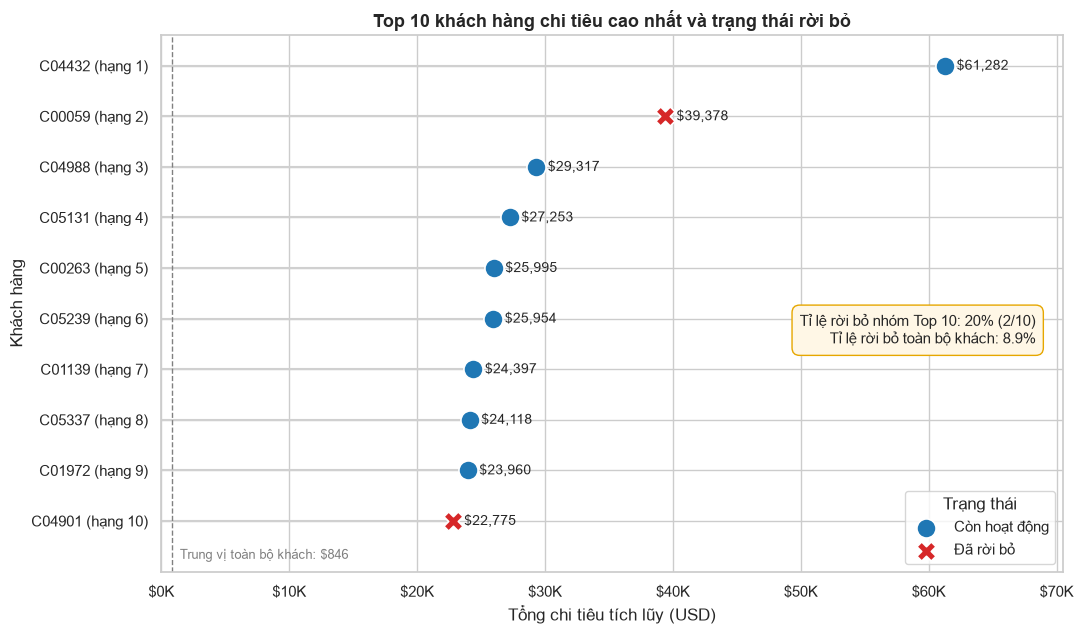

In [6]:
# Dot plot: chi tiêu của Top 10 khách hàng (cao nhất ở trên cùng)
d = top10.sort_values("total_spend_usd")          # đảo thứ tự để khách hạng 1 nằm trên cùng
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.hlines(y, 0, d["total_spend_usd"], color="#d0d0d0", lw=1.5, zorder=1)

# Vẽ riêng từng nhóm trạng thái với màu và ký hiệu khác nhau
kieu = {0: ("Còn hoạt động", "#1f77b4", "o"), 1: ("Đã rời bỏ", "#d62728", "X")}
for trang_thai, (nhan, mau, kyhieu) in kieu.items():
    s = d["churned"] == trang_thai
    ax.scatter(d.loc[s, "total_spend_usd"], y[s.values], s=190, color=mau, marker=kyhieu,
               label=nhan, zorder=3, edgecolor="white", linewidth=1.2)

# Nhãn giá trị bên phải từng điểm
for xi, yi in zip(d["total_spend_usd"], y):
    ax.text(xi + 900, yi, f"${xi:,.0f}", va="center", fontsize=10)

ax.axvline(median_spend, color="gray", ls="--", lw=1)
ax.text(median_spend + 600, -0.75, f"Trung vị toàn bộ khách: ${median_spend:,.0f}", color="gray", fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels([f"{c} (hạng {h})" for c, h in zip(d["customer_id"], d["hang"])])
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
ax.set_xlim(0, d["total_spend_usd"].max() * 1.15); ax.set_ylim(-1, len(d) - 0.4)
ax.set_xlabel("Tổng chi tiêu tích lũy (USD)"); ax.set_ylabel("Khách hàng")
ax.set_title("Top 10 khách hàng chi tiêu cao nhất và trạng thái rời bỏ")
ax.legend(loc="lower right", title="Trạng thái", frameon=True)

# Hộp chú thích tỉ lệ rời bỏ
ax.text(0.97, 0.45, f"Tỉ lệ rời bỏ nhóm Top 10: {churn_top10:.0%} ({k}/{n})\nTỉ lệ rời bỏ toàn bộ khách: {churn_all:.1%}",
        transform=ax.transAxes, ha="right", va="center", fontsize=11,
        bbox=dict(boxstyle="round,pad=0.5", fc="#fff7e6", ec="#e6a700"))
plt.tight_layout()
import os; os.makedirs('../report', exist_ok=True)
plt.savefig('../report/cau9_top10_customers.png', dpi=150, bbox_inches='tight')
plt.show()

### Nhận xét Câu 9

- **Đóng góp doanh thu:** Top 10 có tổng chi tiêu tích lũy khoảng **$304,4 nghìn**, chỉ chiếm ~**2,4%** tổng chi tiêu của 8.000 khách. Doanh thu **không quá tập trung**, nhưng mỗi khách trong nhóm có giá trị rất lớn: khách hạng 1 (C04432, ~$61,3 nghìn) gấp ~72 lần mức chi tiêu trung vị và gấp ~1,6 lần khách hạng 2.
- **Nguy cơ rời bỏ:** 2/10 khách đã rời bỏ (**20%**), gấp ~2,2 lần mặt bằng chung (**8,94%**). Hai trường hợp là C00059 (hạng 2, ~$39,4 nghìn) và C04901 (hạng 10). Chỉ mất riêng C00059 đã tương đương ~13% chi tiêu của cả nhóm.
- **Cẩn trọng khi diễn giải:** nhóm chỉ có 10 người, xác suất nhị thức thấy ≥ 2 ca rời bỏ chỉ do ngẫu nhiên là khoảng 22%, nên chưa đủ để kết luận khách chi tiêu cao *dễ rời bỏ hơn*. Tuy vậy, mỗi ca mất đi rất đắt giá, và có khách chưa rời bỏ nhưng đã lâu không mua (C04988: 139 ngày; C00263: 181 ngày) hoặc có nhiều lượt trả hàng (C05131: 11 lượt).